In [2]:
import capytaine as cpy
import autograd.numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import block_diag
import pygmsh
import gmsh
import os
import xarray as xr
import time

## set colorblind-friendly colormap for plots
plt.style.use('tableau-colorblind10')
print(cpy.__version__)

2.1


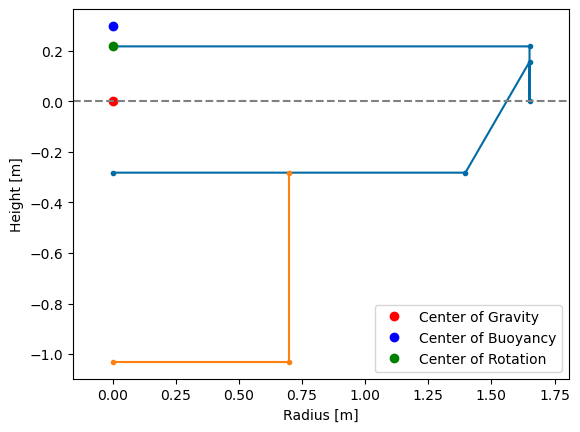

In [3]:
# create mesh
r1 = 3.302/2 # larger/top radius
r2 = 2.794/2 # bottom radius
h1 = 0.5-.439 # cylinder height
h2 = 0.439 # truncated cone height
box_l = 1.397 # box length
box_w = 1.3557 # box width
box_h =  0.7493 # box height
freeboard = 0.218
mesh_size_factor = 0.3

NSIF_flag = True
offset = -8
NSIF_h1 = 0.50
NSIF_h2 = 0.37
NSIF_h3 = 0.37
NSIF_r1 = 0.88
NSIF_r2 = 0.35


# box subtraction
sub_box_flag = False
sub_box_l = box_l
sub_box_w = box_w - .1
sub_box_h = box_h - .05

cg = [0, 0, 0]
cb = [0, 0, .517-freeboard]
cr = [0, 0, freeboard+0] # leaving here, but we'll actually set the center of rotation in WEC-Sim
#cg = [0,0,.242]
#cr = cg

with pygmsh.occ.Geometry() as geom:
    gmsh.option.setNumber('Mesh.MeshSizeFactor', mesh_size_factor)
    cyl = geom.add_cylinder([0, 0, 0],[0, 0, -h1],r1)
    cone = geom.add_cone([0, 0, -h1],[0, 0, -h2],r1,r2)
    box = geom.add_box([0, 0, 0],[box_l,box_w,box_h])

    geom.translate(cyl, [0, 0, freeboard])
    geom.translate(cone, [0, 0, freeboard])
    geom.translate(box, [-box_l/2, -box_w/2, freeboard-h1-h2-box_h])

    if sub_box_flag:
        sub_box1 = geom.add_box([0, 0, 0],[sub_box_l,sub_box_w,sub_box_h])
        sub_box2 = geom.add_box([0.05, 0, -.05],[sub_box_l-.1,sub_box_w,sub_box_h])
        sub_box = geom.boolean_union([sub_box1,sub_box2])
        sub_box = sub_box[0]
        geom.translate(sub_box, [-sub_box_l/2, -sub_box_w/2, freeboard-h1-h2-sub_box_h])
        hollow_box = geom.boolean_difference(box,sub_box)
        geom.boolean_union([hollow_box, cyl, cone])
    else:
        geom.boolean_union([cyl, cone, box])
    
    mesh = geom.generate_mesh() 

if NSIF_flag: 
    with pygmsh.occ.Geometry() as geom:
        gmsh.option.setNumber('Mesh.MeshSizeFactor', mesh_size_factor)
        cyl_NSIF = geom.add_cylinder([0, 0, 0], [0, 0, -NSIF_h1],  NSIF_r1)
        cone1_NSIF   = geom.add_cone([0, 0,  0], [0, 0, NSIF_h2+NSIF_h1], NSIF_r1, NSIF_r2)
        cone2_NSIF   = geom.add_cone([0, 0, -NSIF_h1], [0, 0, -NSIF_h2-NSIF_h1], NSIF_r1, NSIF_r2)
        geom.translate(cone1_NSIF, [0, 0, offset])
        geom.translate(cyl_NSIF, [0, 0, offset])
        geom.translate(cone2_NSIF, [0, 0, offset])
        geom.boolean_union([cone1_NSIF, cyl_NSIF, cone2_NSIF])
        NSIF_mesh = geom.generate_mesh()  

y = [-1*(h1 - freeboard + h2),-1*(h1 - freeboard + h2),-1*(h1 - freeboard),0,freeboard,freeboard]
x = [0,r2,r1,r1,r1,0]
y_box = [-h1-h2+freeboard, -h1-h2-box_h+freeboard, -h1-h2-box_h+freeboard]
x_box = [box_l/2, box_l/2, 0]
plt.plot(x, y,marker='.')
plt.plot(x_box, y_box,marker='.')
plt.plot(cg[0],cg[2],'ro', label='Center of Gravity')
plt.plot(cb[0],cb[2],'bo', label='Center of Buoyancy')
plt.plot(cr[0],cr[2],'go', label='Center of Rotation')
plt.xlim(left=0)
plt.axhline(0, color='grey', linestyle='--')
plt.xlabel('Radius [m]')
plt.ylabel('Height [m]')
plt.axis('equal')
plt.legend()


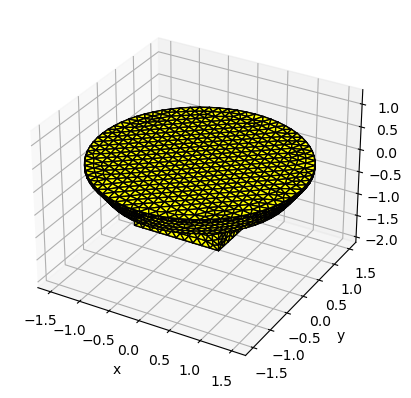

ValueError: Trying to compute hydrostatics for Pioneer, but no center of mass has been defined.
Suggested solution: define a `center_of_mass` attribute for the FloatingBody Pioneer.

In [7]:
pnr_fb = cpy.FloatingBody.from_meshio(mesh, name="Pioneer")
if NSIF_flag:
    NSIF_fb = cpy.FloatingBody.from_meshio(NSIF_mesh, name="NSIF")


pnr_fb.show_matplotlib()
#pnr_fb.keep_immersed_part(free_surface=0)
#pnr_fb.show_matplotlib()
pnr_mesh = pnr_fb.mesh
pnr_fb.show()

hs = pnr_fb.compute_hydrostatics()
print(hs['center_of_buoyancy'])

import capytaine.io.mesh_writers

# save as gdf using meshmagick
#capytaine.io.mesh_writers.write_GDF('pnr_with_box_refined_size3.gdf', pnr_mesh.vertices, pnr_mesh.faces,ulen=1)

